In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report, ConfusionMatrixDisplay
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input,Dense

In [3]:
df = pd.read_csv("Churn_Modelling.csv")

In [5]:
X = df.drop(columns=["RowNumber","CustomerId","Surname","Exited"])
y = df["Exited"]

In [6]:
X = pd.get_dummies(X,columns=["Geography","Gender"],drop_first=True,dtype=int)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)


In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



In [9]:
model = Sequential([Input(shape=(X_train_scaled.shape[1],)),
                   Dense(16,activation="relu"),
                   Dense(8,activation="relu"),
                   Dense(1,activation="sigmoid")])

In [10]:
model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])

In [11]:
history = model.fit(X_train_scaled,y_train,epochs=50,batch_size=32,validation_split=0.2,verbose=1)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.7506 - loss: 0.5535 - val_accuracy: 0.7994 - val_loss: 0.4781
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 985us/step - accuracy: 0.8055 - loss: 0.4504 - val_accuracy: 0.8181 - val_loss: 0.4347
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8194 - loss: 0.4191 - val_accuracy: 0.8244 - val_loss: 0.4139
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8267 - loss: 0.4054 - val_accuracy: 0.8369 - val_loss: 0.4003
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 983us/step - accuracy: 0.8338 - loss: 0.3946 - val_accuracy: 0.8462 - val_loss: 0.3878
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8403 - loss: 0.3844 - val_accuracy: 0.8500 - val_loss: 0.3750
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 995us/step - accuracy: 0.8475 - loss: 0.3739 - val_accuracy: 0.8531 - val_loss: 0.3643
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8486 - loss: 0.3653 - val_accura

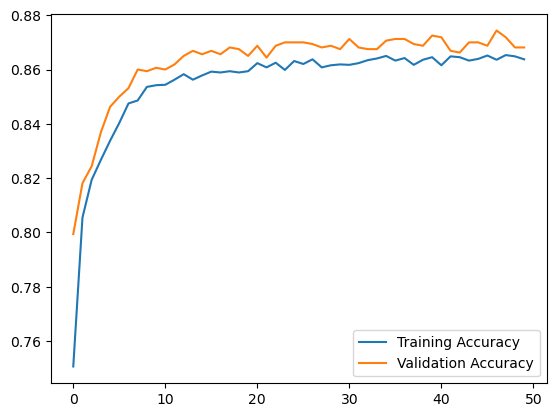

In [12]:
plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
plt.legend()
plt.show()

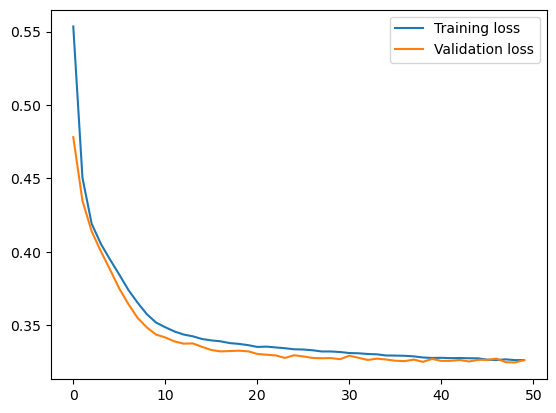

In [13]:
plt.plot(history.history["loss"],label="Training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.legend()
plt.show()

In [14]:
probabilities = model.predict(X_test_scaled,verbose=0).ravel()
y_pred = (probabilities >=0.5).astype(int)

In [15]:
accuracy = accuracy_score(y_test,y_pred)
cm = confusion_matrix(y_test,y_pred)

print(f"accuracy is {accuracy}")
print(f"confusion matrix is {cm}")

accuracy is 0.863
confusion matrix is [[1526   67]
 [ 207  200]]


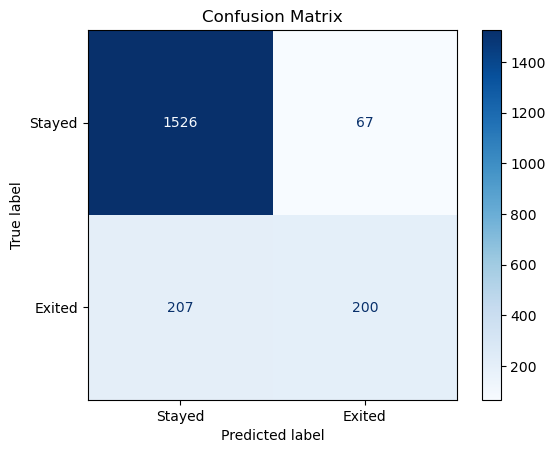

In [16]:
ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Stayed","Exited"]).plot(cmap="Blues",values_format="d")
plt.title("Confusion Matrix")
plt.show()